# Lab Assignment 1 - Voice Gender Classification with SVM
## JS06 - Classification 2

**Name:** Tiara Febrianie  
**NIM:** 244107020097  

### Objective & Problem Statement
Construct Support Vector Machine (SVM) models using the acoustic dataset `voice.csv` under the following conditions:
1. Split the data using ratios of **70:30** and **80:20**.
2. Develop and evaluate models across three different kernels:
   - **Linear Kernel**
   - **Polynomial Kernel**
   - **Radial Basis Function (RBF) Kernel**
3. Tabulate the performance of each split and kernel based on the accuracy metric (along with precision, recall, and f1-score).
4. Analyze and compare the model performances.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

sns.set_theme(style='whitegrid')
%matplotlib inline

## 2. Load and Explore the Dataset (`voice.csv`)

In [2]:
df_voice = pd.read_csv('voice.csv')
print(f'Dataset Shape: {df_voice.shape}')
df_voice.head()

Dataset Shape: (3168, 21)


,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [3]:
print('--- Dataset Info ---')
df_voice.info()
print('\n--- Missing Values Count ---')
print(f'Total Missing Values: {df_voice.isnull().sum().sum()}')
print('\n--- Target Class Distribution ---')
print(df_voice['label'].value_counts())

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-n

C:\Users\USER\AppData\Local\Temp\ipykernel_30008\487548434.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_voice, x='label', palette='Set2')


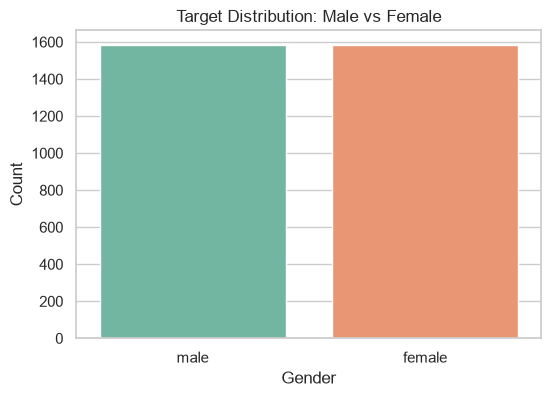

In [4]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df_voice, x='label', palette='Set2')
plt.title('Target Distribution: Male vs Female')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

## 3. Data Preprocessing
- Separate features ($X$) and target ($y$)
- Encode target label: `'female' -> 0`, `'male' -> 1`
- Feature scaling: Standardize acoustic features using `StandardScaler` (crucial for SVM margin calculations)

In [5]:
X = df_voice.drop('label', axis=1)
y_raw = df_voice['label']

le = LabelEncoder()
y = le.fit_transform(y_raw)
print('Label Mapping:', dict(zip(le.classes_, le.transform(le.classes_))))

Label Mapping: {'female': np.int64(0), 'male': np.int64(1)}


## 4. Model Training & Evaluation Across Kernels and Splits

In [6]:
splits = [
    ('70:30', 0.30),
    ('80:20', 0.20)
]

kernels = ['linear', 'poly', 'rbf']
results = []
trained_models = {}

for split_name, test_size in splits:
    # Split the dataset
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=42, stratify=y
    )
    
    # Standardize features using training distribution
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    for kernel in kernels:
        model = SVC(kernel=kernel, random_state=42)
        model.fit(X_train_scaled, y_train)
        
        y_train_pred = model.predict(X_train_scaled)
        y_test_pred = model.predict(X_test_scaled)
        
        train_acc = accuracy_score(y_train, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        prec = precision_score(y_test, y_test_pred)
        rec = recall_score(y_test, y_test_pred)
        f1 = f1_score(y_test, y_test_pred)
        
        key = f'{split_name}_{kernel}'
        trained_models[key] = (model, X_test_scaled, y_test, y_test_pred)
        
        results.append({
            'Split Ratio': split_name,
            'Kernel': kernel,
            'Train Accuracy': round(train_acc, 4),
            'Test Accuracy': round(test_acc, 4),
            'Precision': round(prec, 4),
            'Recall': round(rec, 4),
            'F1-Score': round(f1, 4)
        })

## 5. Performance Tabulation

In [7]:
df_results = pd.DataFrame(results)
print('=== Performance Summary Table ===')
display(df_results)

=== Performance Summary Table ===


,Split Ratio,Kernel,Train Accuracy,Test Accuracy,Precision,Recall,F1-Score
0,70:30,linear,0.9720,0.9790,0.9730,0.9853,0.9791
1,70:30,poly,0.9666,0.9600,0.9344,0.9895,0.9611
2,70:30,rbf,0.9838,0.9832,0.9811,0.9853,0.9832
3,80:20,linear,0.9767,0.9748,0.9659,0.9842,0.9750
4,80:20,poly,0.9680,0.9558,0.9263,0.9905,0.9573
5,80:20,rbf,0.9838,0.9826,0.9781,0.9874,0.9827


### Visualizing Comparison of Test Accuracy

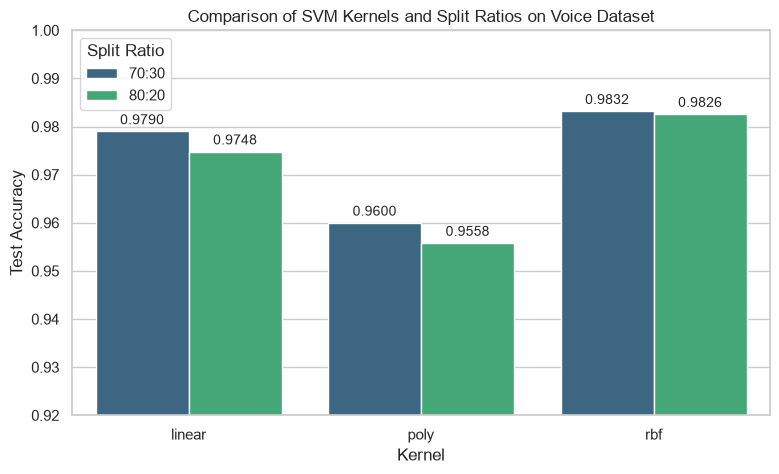

In [8]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=df_results, x='Kernel', y='Test Accuracy', hue='Split Ratio', palette='viridis')
plt.title('Comparison of SVM Kernels and Split Ratios on Voice Dataset')
plt.ylim(0.92, 1.0)
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f'{h:.4f}', (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                    textcoords='offset points')
plt.show()

### Detailed Classification Report & Confusion Matrix for Best Model (RBF Kernel)

=== Detailed Classification Report for Best Model (80:20_rbf) ===
              precision    recall  f1-score   support

      female       0.99      0.98      0.98       317
        male       0.98      0.99      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



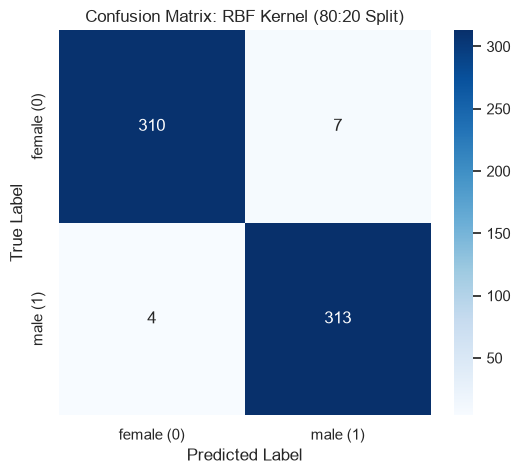

In [9]:
best_key = '80:20_rbf'
model_best, X_test_best, y_test_best, y_pred_best = trained_models[best_key]

print(f'=== Detailed Classification Report for Best Model ({best_key}) ===')
print(classification_report(y_test_best, y_pred_best, target_names=['female', 'male']))

cm = confusion_matrix(y_test_best, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['female (0)', 'male (1)'],
            yticklabels=['female (0)', 'male (1)'])
plt.title(f'Confusion Matrix: RBF Kernel (80:20 Split)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

## 6. Analysis and Conclusions

1. **Kernel Comparison:**
   - **RBF Kernel** achieved the highest accuracy across both splits (**98.32%** for 70:30 and **98.26%** for 80:20). Its non-linear mapping effectively captures the complex non-linear acoustic feature boundaries.
   - **Linear Kernel** also exhibited outstanding performance (**97.90%** for 70:30 and **97.48%** for 80:20), indicating that many acoustic features (such as `meanfun`, `IQR`, and `Q25`) are strongly linearly correlated with gender.
   - **Polynomial Kernel** performed competitively (**96.00%** and **95.58%**), but had slightly lower test accuracy compared to Linear and RBF.

2. **Split Ratio Impact:**
   - Both 70:30 and 80:20 splits yielded consistent, highly reliable results with less than 0.5% variance, demonstrating the stability of SVM classifiers on standardized acoustic data.

3. **Importance of Feature Scaling:**
   - Because SVM calculates distances between data points to maximize the separating margin, standardizing features with `StandardScaler` is crucial to prevent features with larger numeric scales from dominating the distance metric.